АНАЛИЗ ВРЕМЕННОГО РЯДА НА СЕЗОННОСТЬ

In [12]:
import pandas as pd
from statsmodels.tsa.seasonal import STL
import matplotlib.pyplot as plt
df = pd.read_csv(r"C:\курсовая_семичевский\data\raw\moex_stocks_panel.csv")
df_ALRS = df[df['ticker'] == 'ALRS']
df_ALRS.dropna()

df['begin'] = pd.to_datetime(df['begin'])
df = df.set_index('begin')
final_tickers = ['SBER', 'GAZP', 'VTBR', 'LKOH', 'ROSN', 'PLZL', 'GMKN',
                 'SELG', 'RUAL', 'MGNT', 'ALRS', 'MTSS', 'IRAO']

df = df[df['ticker'].isin(final_tickers)].copy()

df_month = df.groupby('ticker').resample('ME').last().reset_index()

df_month = df_month.dropna()
df_month


,ticker,begin,open,close,high,low,value,volume
0,ALRS,2015-01-31,76.560,78.490,80.260,76.560,5.009149e+08,6414000
1,ALRS,2015-02-28,69.250,68.500,70.460,67.320,4.830561e+08,7065700
2,ALRS,2015-03-31,71.330,72.000,72.790,69.750,4.500374e+08,6335800
3,ALRS,2015-04-30,69.280,68.390,69.280,67.200,2.716412e+08,3992900
4,ALRS,2015-05-31,68.490,63.250,69.250,63.250,8.131017e+08,12201200
...,...,...,...,...,...,...,...,...
1787,VTBR,2026-02-28,86.900,86.255,87.150,85.800,2.289110e+09,26522014
1788,VTBR,2026-03-31,83.505,86.045,86.180,82.935,6.554005e+09,77288385
1789,VTBR,2026-04-30,92.930,91.300,93.200,90.655,3.657336e+09,40005922
1790,VTBR,2026-05-31,78.900,78.985,79.015,78.880,1.931033e+08,2445829


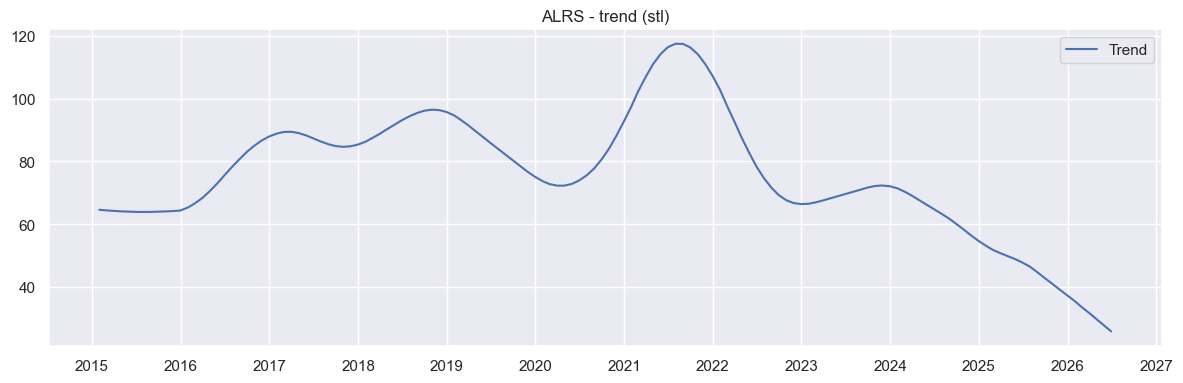

In [13]:
def check_trend_stl(ticker, df):
    from statsmodels.tsa.seasonal import STL
    import matplotlib.pyplot as plt
    import matplotlib.dates as mdates

    series = df[df['ticker'] == ticker].set_index('begin')['open']
    series = series.asfreq('ME')

    stl = STL(series, period=12)
    result = stl.fit()

    trend = result.trend

    plt.figure(figsize=(12, 4))
    plt.plot(trend, label='Trend')
    plt.legend(loc='upper right')
    plt.title(f'{ticker} - trend (stl)')
    plt.gca().xaxis.set_major_locator(mdates.YearLocator(1))
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    plt.tight_layout()
    plt.show()
check_trend_stl('ALRS', df_month)

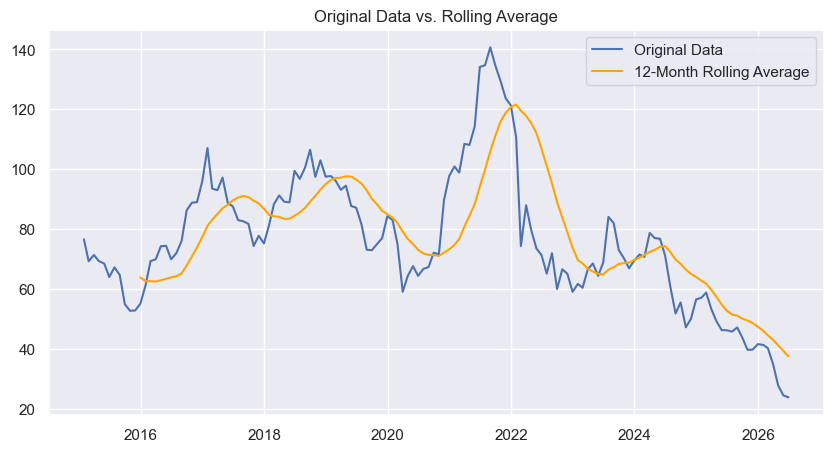

In [14]:
# Расчет скользящего среднего за 12 месяцев
df_month_alrs = df_month[df_month['ticker'] == 'ALRS'].copy()
df_month_alrs['rolling_avg'] = df_month_alrs['open'].rolling(window=12).mean()

plt.figure(figsize=(10, 5))
plt.plot(df_month_alrs['begin'], df_month_alrs['open'], label='Original Data')
plt.plot(df_month_alrs['begin'], df_month_alrs['rolling_avg'], label='12-Month Rolling Average', color='orange')
plt.title('Original Data vs. Rolling Average')
plt.legend()
plt.show()

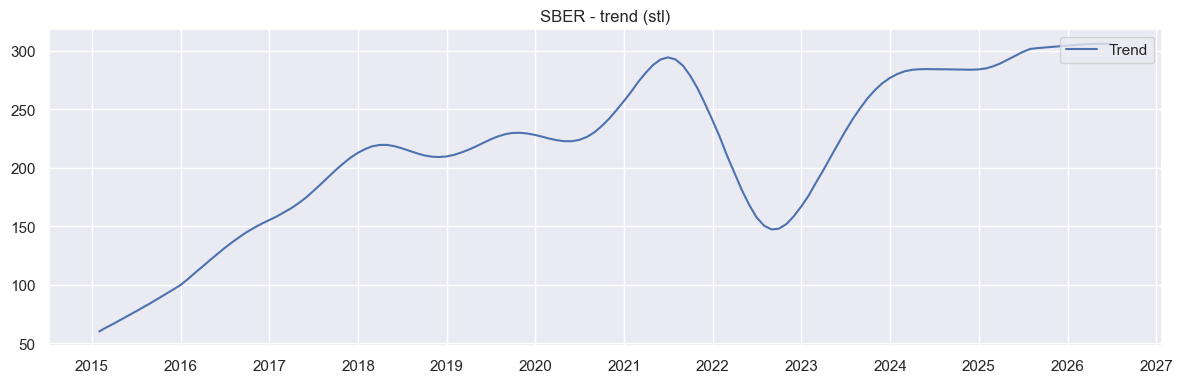

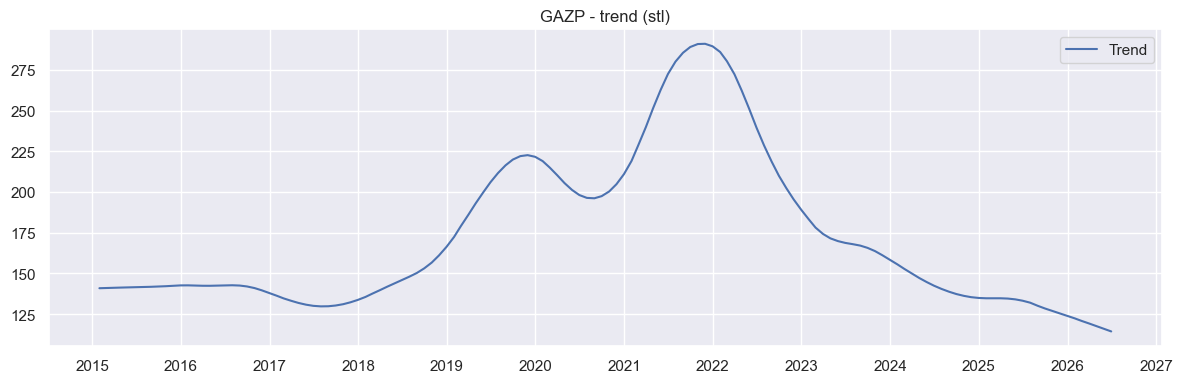

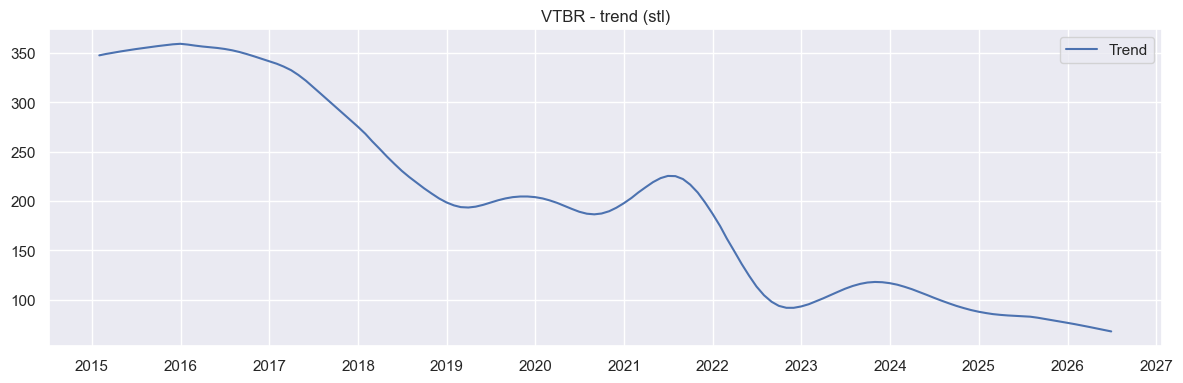

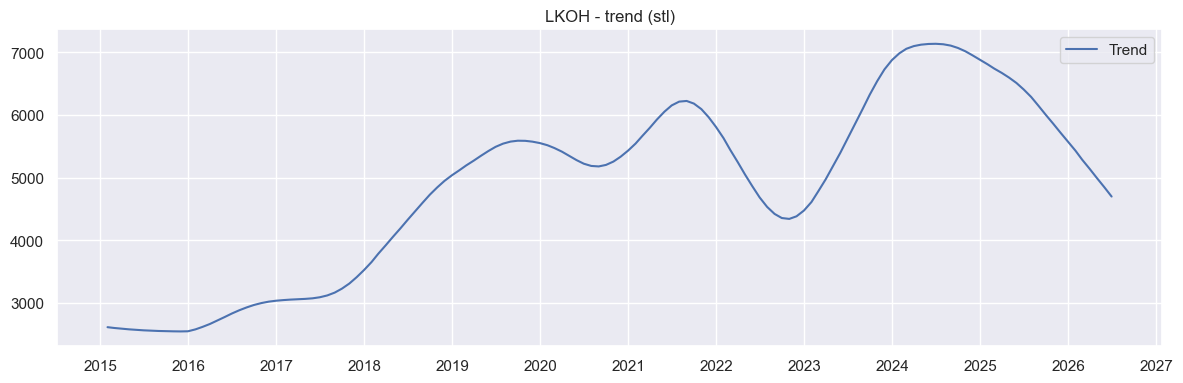

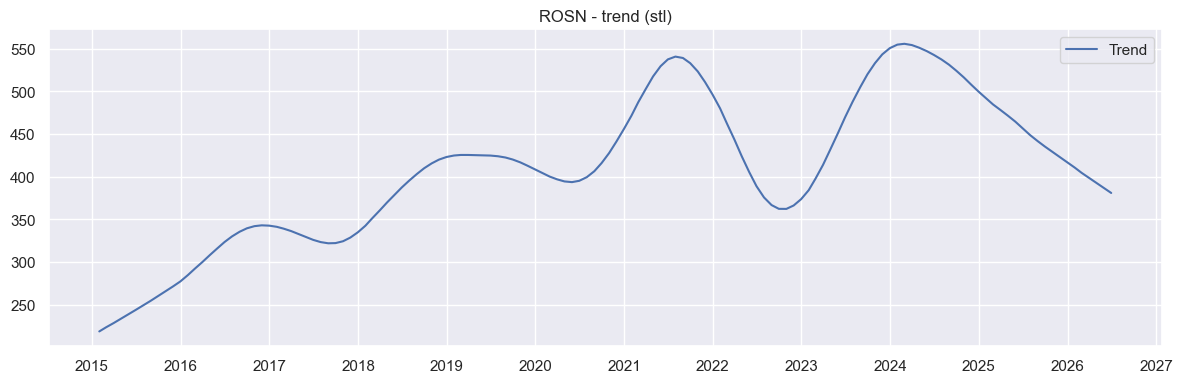

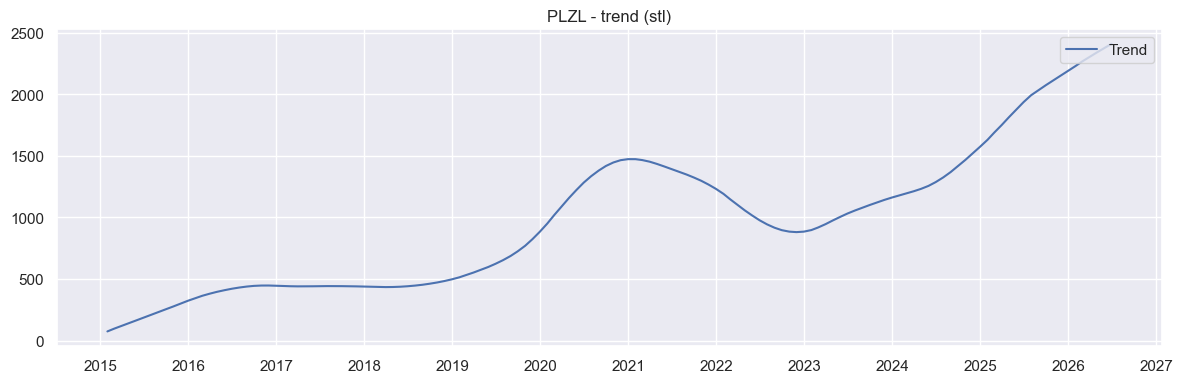

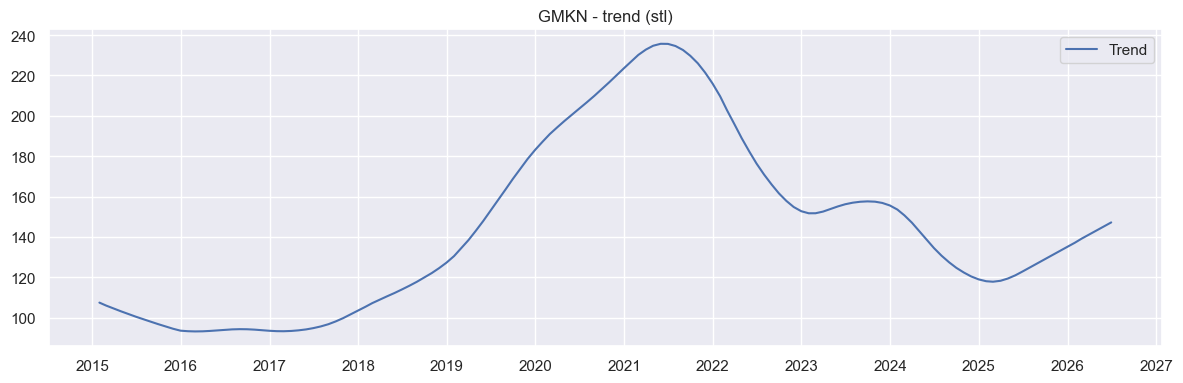

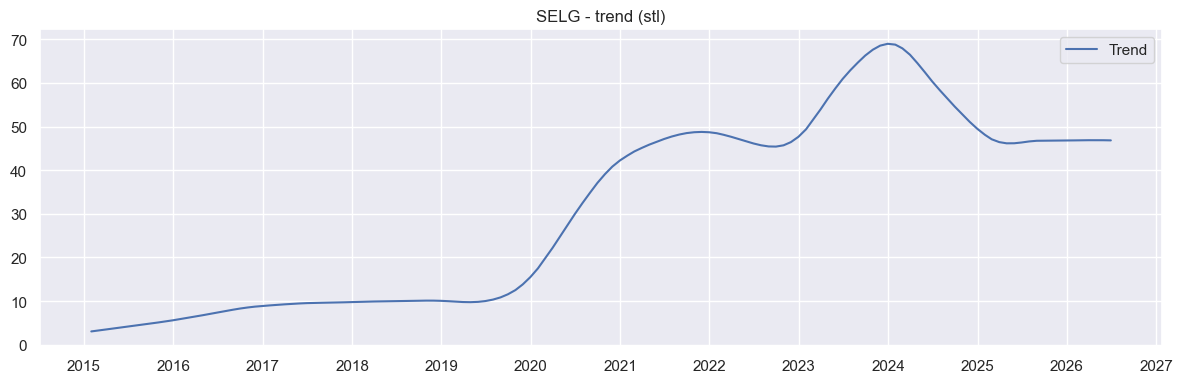

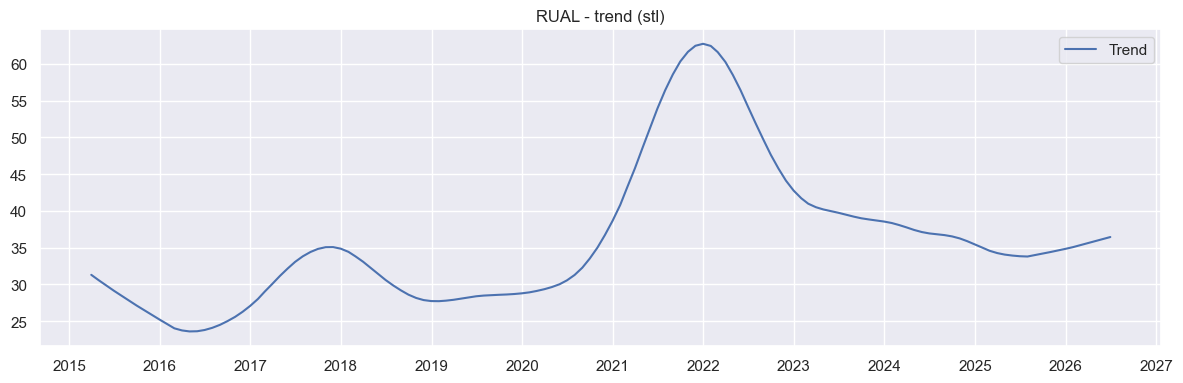

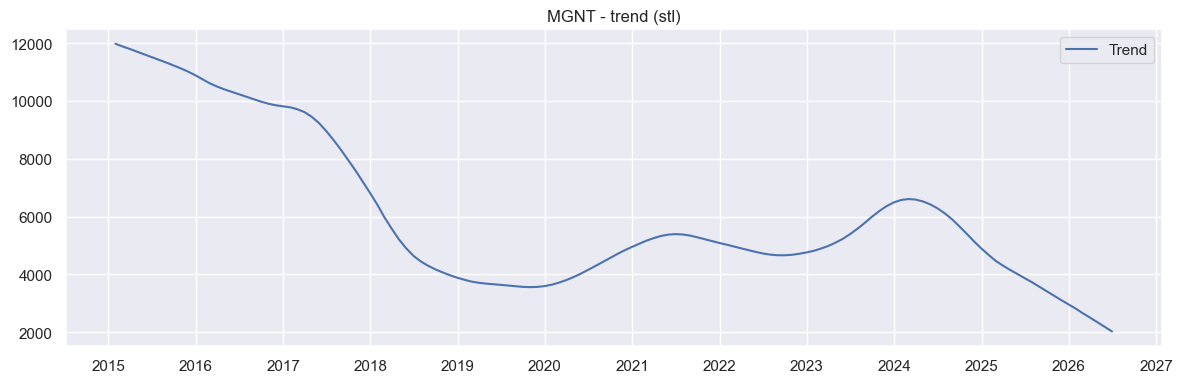

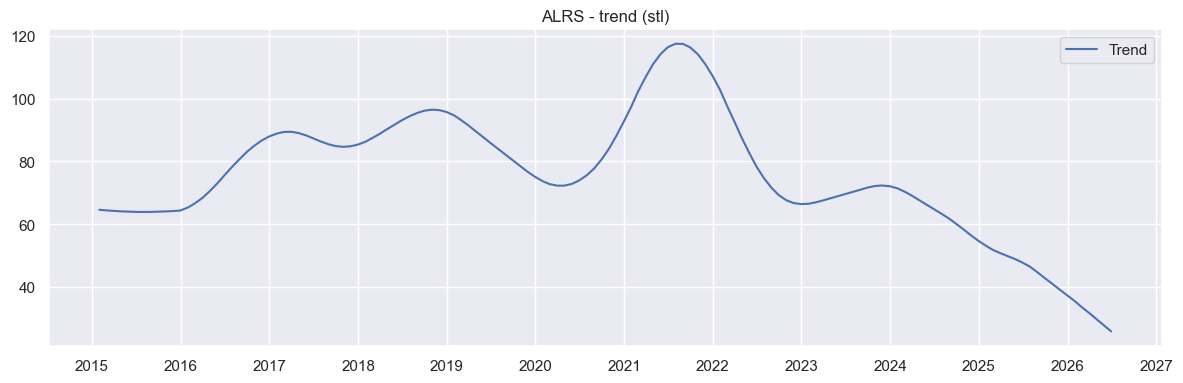

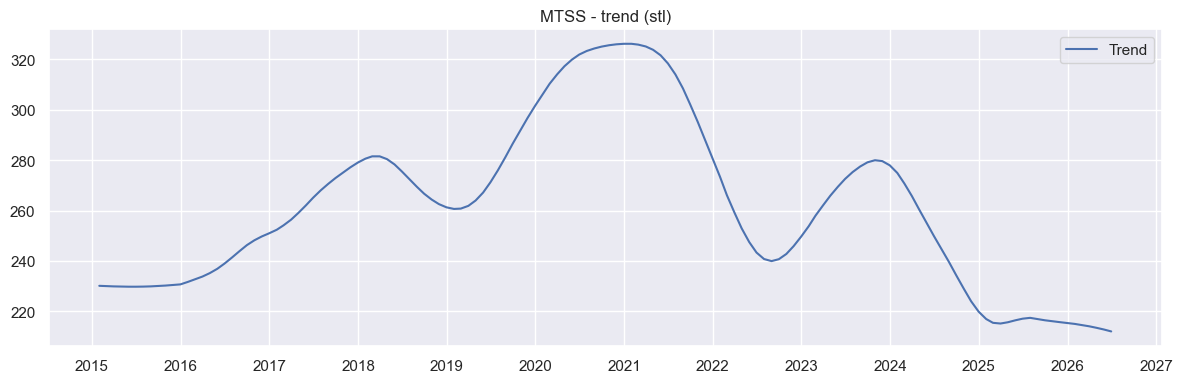

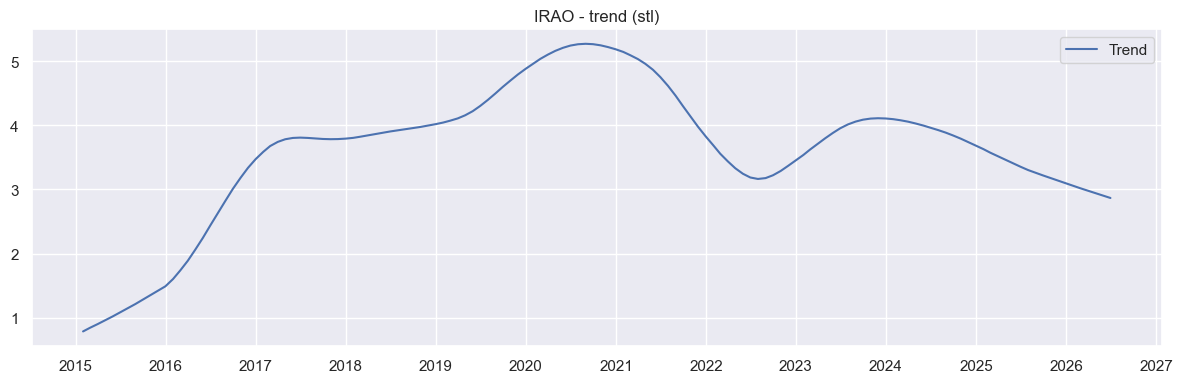

In [15]:
tickers_lst = ['SBER', 'GAZP', 'VTBR', 'LKOH',
                        'ROSN', 'PLZL', 'GMKN',
                        'SELG', 'RUAL', 'MGNT', 'ALRS', 'MTSS', 'IRAO']
for tick in tickers_lst:
    check_trend_stl(tick, df_month)


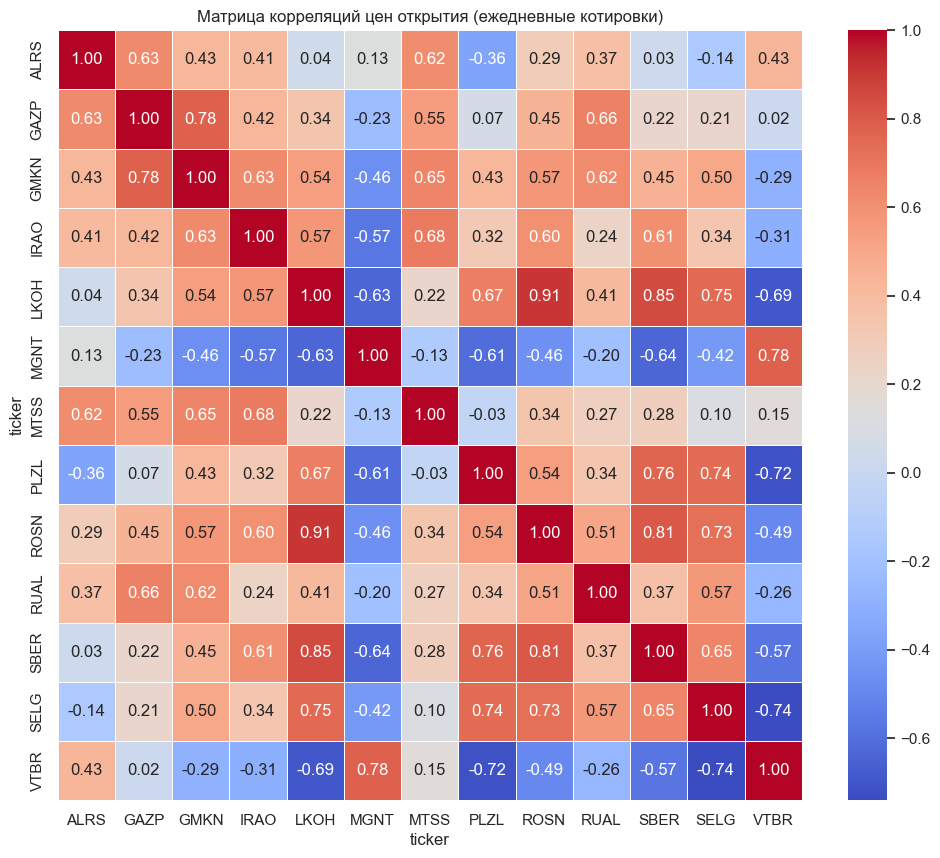

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Преобразуем данные в широкий формат: даты по строкам, тикеры по колонкам
prices_open = df.pivot(columns='ticker', values='open')

corr_matrix = prices_open.corr()

# 3. Визуализируем с помощью тепловой карты
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Матрица корреляций цен открытия (ежедневные котировки)')
plt.show()

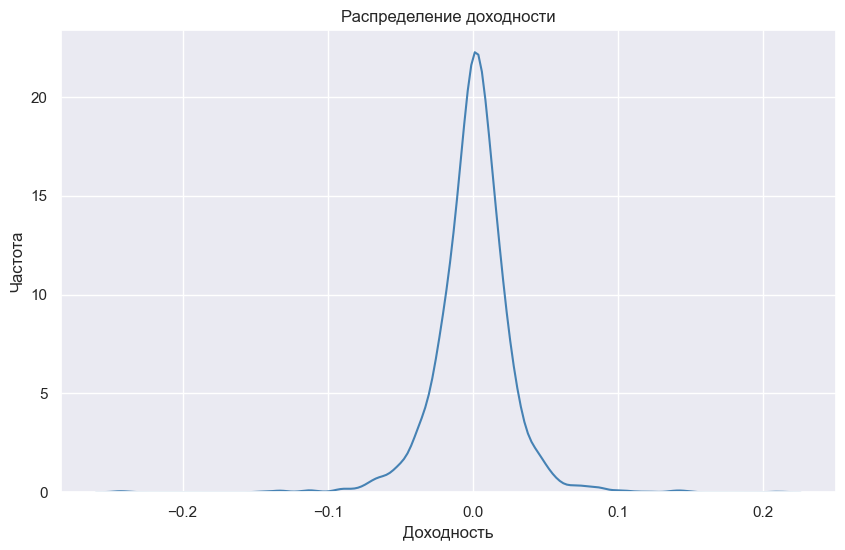

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df_macro = pd.read_csv(r"C:\курсовая_семичевский\data\raw\df_macro.csv")

plt.figure(figsize=(10,6))
sns.kdeplot(data=df_macro, x='brent_return', color="steelblue")
plt.title('Распределение дневной доходности фьючерса на нефть')
plt.xlabel('Доходность brent')
plt.ylabel('Частота')
plt.show()

In [18]:
import os
import pandas as pd

folder = r"C:\курсовая_семичевский\data\raw"

brent_path = os.path.join(folder, "df_macro.csv")
fx_path = os.path.join(folder, "usdrub.csv")

# Загрузка Brent
df_macro = pd.read_csv(
    brent_path,
    parse_dates=["date"],
    index_col="date"
)

# Загрузка USD/RUB
df_fx = pd.read_csv(
    fx_path,
    parse_dates=["date"],
    index_col="date"
)

# Добавляем USD/RUB по совпадающим датам
df_macro = df_macro.join(df_fx, how="inner")

# Удаляем наблюдения с пропусками в доходностях
df_macro = df_macro.dropna(
    subset=["brent_return", "usdrub_return"]
)

print(df_macro.head())
print(df_macro.tail())
print(f"Итоговое количество наблюдений: {len(df_macro)}")

            brent_close  brent_return  usdrub_close  usdrub_return
date                                                              
2015-01-05    53.110001     -0.058667     58.750000       0.007287
2015-01-06    51.099998     -0.037846     60.832001       0.035438
2015-01-07    51.150002      0.000979     63.160000       0.038269
2015-01-08    50.959999     -0.003715     62.650002      -0.008075
2015-01-09    50.110001     -0.016680     60.250000      -0.038308
            brent_close  brent_return  usdrub_close  usdrub_return
date                                                              
2026-06-03    97.809998      0.018854     73.196777       0.016663
2026-06-04    95.029999     -0.028422     73.747688       0.007526
2026-06-05    93.089996     -0.020415     73.397400      -0.004750
2026-06-08    94.250000      0.012461     73.682243       0.003881
2026-06-09    91.449997     -0.029708     72.971115      -0.009651
Итоговое количество наблюдений: 2871


count     2871.000000
mean         4.077946
std        194.389911
min        -99.020548
25%         -0.551057
50%          0.000000
75%          0.566522
max      10315.387020
Name: usdrub_return_pct, dtype: float64
            usdrub_close  usdrub_return  usdrub_return_pct
date                                                      
2016-01-07     74.595001     103.153870       10315.387020
2023-03-17     76.464996      14.292999        1429.299927
2022-06-13    110.674103       0.909326          90.932636
2022-07-18    110.674103       0.900311          90.031078
2022-03-21    132.088699       0.281295          28.129502
2022-03-08    138.965103       0.276724          27.672355
2022-03-01    104.973503       0.260776          26.077637
2022-07-06     63.465099       0.164497          16.449724
2022-12-20     69.714996       0.075185           7.518508
2020-03-19     80.919998       0.074670           7.467044
2022-04-11     85.089996       0.074165           7.416525
2023-02-03     75

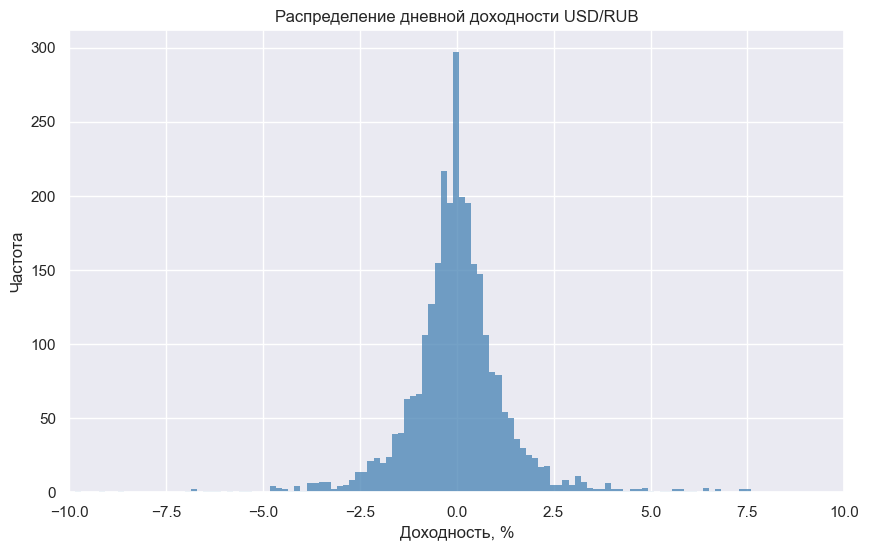

In [19]:
import numpy as np

df_macro["usdrub_return_pct"] = df_macro["usdrub_return"] * 100

print(df_macro["usdrub_return_pct"].describe())

print(
    df_macro.nlargest(15, "usdrub_return_pct")[
        ["usdrub_close", "usdrub_return", "usdrub_return_pct"]
    ]
)

bad_mask = (
    (df_macro["usdrub_close"] <= 0)
    | (~np.isfinite(df_macro["usdrub_return"]))
    | (df_macro["usdrub_return"].abs() > 1)
)

print(df_macro.loc[
    bad_mask,
    ["usdrub_close", "usdrub_return", "usdrub_return_pct"]
])
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_macro,
    x="usdrub_return_pct",
    color="steelblue"
)

plt.xlim(-10, 10)
plt.title("Распределение дневной доходности USD/RUB")
plt.xlabel("Доходность, %")
plt.ylabel("Частота")
plt.show()

In [20]:
df_macro["usdrub_return_lag1"] = df_macro["usdrub_return"].shift(1)
df_macro

,brent_close,brent_return,usdrub_close,usdrub_return,usdrub_return_pct,usdrub_return_lag1
date,,,,,,
2015-01-05,53.110001,-0.058667,58.750000,0.007287,0.728674,NaN
2015-01-06,51.099998,-0.037846,60.832001,0.035438,3.543831,0.007287
2015-01-07,51.150002,0.000979,63.160000,0.038269,3.826932,0.035438
2015-01-08,50.959999,-0.003715,62.650002,-0.008075,-0.807470,0.038269
2015-01-09,50.110001,-0.016680,60.250000,-0.038308,-3.830808,-0.008075
...,...,...,...,...,...,...
2026-06-03,97.809998,0.018854,73.196777,0.016663,1.666317,0.010795
2026-06-04,95.029999,-0.028422,73.747688,0.007526,0.752644,0.016663
2026-06-05,93.089996,-0.020415,73.397400,-0.004750,-0.474982,0.007526


In [21]:
import pandas as pd
import numpy as np
df_gold = pd.read_csv(r"C:\курсовая_семичевский\data\raw\gold_daily.csv")
df_gold['daily_return'] = df_gold['close'].pct_change()
df_gold

,begin,ticker,open,close,high,low,daily_return
0,2015-01-12,GOLD,2440.5,2478.9,2478.9,2440.5,NaN
1,2015-01-13,GOLD,2560.9,2611.5,2618.0,2560.9,0.053491
2,2015-01-14,GOLD,2620.0,2643.0,2643.0,2618.7,0.012062
3,2015-01-15,GOLD,2563.7,2608.7,2642.2,2563.7,-0.012978
4,2015-01-16,GOLD,2646.0,2675.0,2675.0,2640.0,0.025415
...,...,...,...,...,...,...,...
2746,2026-06-04,GOLD,10518.2,10478.3,10645.7,10445.7,0.004833
2747,2026-06-05,GOLD,10442.4,10205.4,10500.0,10188.8,-0.026044
2748,2026-06-08,GOLD,10134.6,10107.9,10183.5,9991.1,-0.009554
2749,2026-06-09,GOLD,10034.0,9815.0,10034.0,9781.0,-0.028977


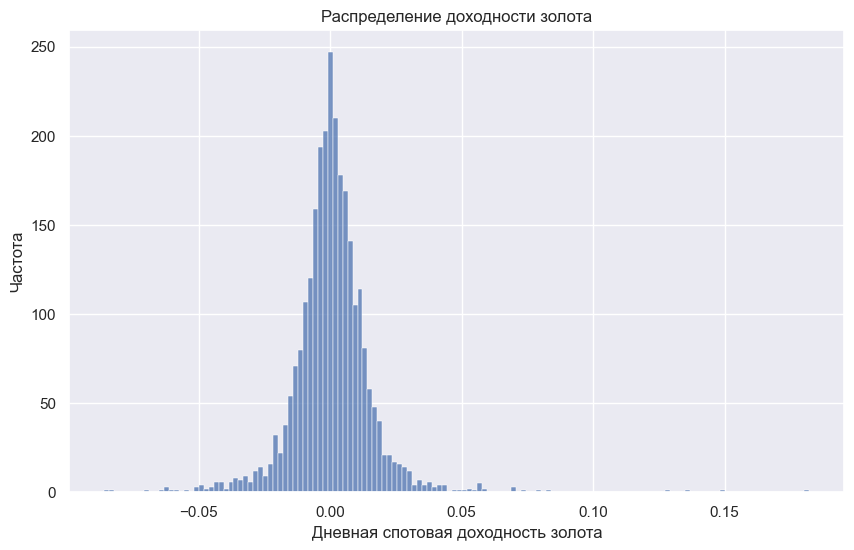

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))
sns.set_theme()
sns.histplot(data=df_gold, x='daily_return')
plt.xlabel('Дневная спотовая доходность золота')
plt.ylabel('Частота')
plt.title('Распределение доходности золота')
plt.show()